<a href="https://colab.research.google.com/github/eojin22/ESAA/blob/main/OB_WEEK11_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 7.5. LSTM
RNN의 단점: 가중치가 업데이트되는 과정에서 기울기가 1보다 작은 값이 계속 곱해지기 때문에 기울기가 사라지는 기울기 소멸 문제 발생 => LSTM, GRU같이 확장된 RNN 방식들로 해결

## 7.5.1 LSTM 구조
**LTSM 순전파**

LSTM: 기울기 소멸 문제를 해결하기 위해 망각 게이트, 입력 게이트, 출력 게이트라는 새로운 요소를 은닉층의 각 뉴런에 추가

> 망각 게이트(forget gatc)
- 과거 정보를 어느 정도 기억할지 결정.
- 과거 정보와 현재 데이터를 입력받아 시그모이드를 취한 후 그 값을 과거 정보에 곱해줌. 따라서 시그모이드의 출력이 0이면 과거 정보는 버리고 1이면 과거 정보는 온전히 보존.

> 입력 게이트(input gate)
- 현재 정보를 기억하기 위해 만들어짐. 과거 정보와 현재 데이터 를 입력받아 시그모이드와 하이퍼볼력 탄젠트 함수를 기반으로 현재 정보에 대한 보존량을 결정.

>셀
- 각 단계에 대한 은닉 노드를 메모리 셀이라고 함. 망각 게이트와 입력 게이트의 이전 단계 셀 정보를 계산하여 현재 단계의 셀 상태를 업데이트

> 출력 게이트
- 과거 정보와 현재 데이터를 시용하여 뉴런의 출력을 결정. 이전 은닉 상태와 t번째 입력을 고려해서 다음 은닉 상태를 계산함.
- LSTM에서는 이 은닉 상태가 그 시점에서의 출력이 됨.

**LSTM 역전파**
- LSTM은 셀을 통해서 역전파를 수행하기 때문에 '중단 없는 기울기'라고도 함
- 셀 단위로 오차가 전파된다고 해서 입력 방향으로 오차가 전파되지 않는 것은 아님. 셀 내부적으로는 오차가 입력으로 전파됨.

###**7.5.2 LSTM 셀 구현**

In [ ]:
# 라이브러리 호출

import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision.datasets as dataset
from torch.autograd import Variable
from torch.nn import Parameter
from torch import Tensor
import torch.nn.functional as F
from torch.utils.data import DataLoader
import math

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
cuda = True if torch.cuda.is_available() else False

Tensor = torch.cuda.FloatTensor if cuda else torch.FloatTensor

torch.manual_seed(125)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(125)

In [ ]:
# 데이터 전처리

import torchvision.transforms as transforms

mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (1.0,))
])

In [ ]:
# 데이터셋 내려받기

from torchvision.datasets import MNIST

download_root = './data/MNIST_DATASET'
train_dataset = MNIST(download_root, transform=mnist_transform, train=True, download=True)
valid_dataset = MNIST(download_root, transform=mnist_transform, train=False, download=True)
test_dataset = MNIST(download_root, transform=mnist_transform, train=False, download=True)

100%|██████████| 9.91M/9.91M [00:00<00:00, 52.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 2.20MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 13.4MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.58MB/s]


- train_loader, valid_loader, test_loader가 호출될 때 메모리로 불러온다는 점에 주의

In [ ]:
# 데이터셋을 메모리로 가져오기
batch_size = 64
train_loader = DataLoader(dataset=train_dataset, batch_size = batch_size, shuffle=True)
valid_loader = DataLoader(dataset=test_dataset, batch_size = batch_size, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size = batch_size, shuffle=True)

In [ ]:
# 변수 값 지정
batch_size = 100
n_iters = 6000
num_epochs = n_iters / (len(train_dataset) / batch_size)
num_epochs = int(num_epochs)

In [ ]:
# LSTM 셀 네트워크 구축
class LSTMCell(nn.Module):
  def __init__(self, input_size, hidden_size, bias = True):
    super(LSTMCell, self).__init__()
    self.input_size = input_size
    self.hidden_size = hidden_size
    self.bias = bias
    self.x2h = nn.Linear(input_size, 4*hidden_size, bias = bias)
    self.h2h = nn.Linear(hidden_size, 4*hidden_size, bias = bias)
    self.reset_parameters()

  # 모델의 파라미터 초기화
  def reset_parameters(self):
    std = 1.0 / math.sqrt(self.hidden_size)
    for w in self.parameters():
      w.data.uniform_(-std, std)

  def forward(self, x, hidden):
    hx, cx = hidden
    x = x.view(-1, x.size(1))

    gates = self.x2h(x) + self.h2h(hx)
    gates = gates.squeeze()
    ingate, forgetgate, cellgate, outgate = gates.chunk(4, 1)

    ingate = F.sigmoid(ingate) # 입력 게이트에 시그모이드 활성화 함수 적용
    forgetgate = F.sigmoid(forgetgate) # 망각 게이트에 시그모이드 활성화 함수 적용
    cellgate = F.tanh(cellgate) # 셀 게이트에 탄젠트 활성화 함수 적용
    outgate = F.sigmoid(outgate) # 출력 게이트에 시그모이드 활성화 함수 적용

    cy = torch.mul(cx, forgetgate) + torch.mul(ingate, cellgate)
    hy = torch.mul(outgate, F.tanh(cy))
    return(hy, cy)

In [ ]:
# LSTM 셀의 전반적인 네트워크

class LSTMModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, layer_dim, output_dim, bias=True):
        super(LSTMModel, self).__init__()
        self.hidden_dim = hidden_dim # 은닉층의 뉴런/유닛 개수

        self.layer_dim = layer_dim
        self.lstm = LSTMCell(input_dim, hidden_dim, layer_dim)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        if torch.cuda.is_available():
            h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda()) # 은닉 상태를 0으로 초기화
        else:
            h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim))

        if torch.cuda.is_available():
            c0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda()) # 셀 상태를 0으로 초기화
        else:
            c0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim))

        outs = []
        cn = c0[0, :, :] # 셀 상태에 대한 텐서
        hn = h0[0, :, :] # 은닉 상태에 대한 텐서

        for seq in range(x.size(1)): # LSTM 셀 계층을 반복하여 쌓아 올림
            hn, cn = self.lstm(x[:, seq, :], (hn, cn)) # 은닉 상태와 셀 상태를 LSTMCell에 적용한 결과를 다시 저장
            outs.append(hn)

        out = outs[-1].squeeze()
        out = self.fc(out)
        return out

In [ ]:
# 옵티마이저와 손실 함수 지정
input_dim = 28
hidden_dim = 128
layer_dim = 1
output_dim = 10

model = LSTMModel(input_dim, hidden_dim, layer_dim, output_dim)
if torch.cuda.is_available(): # GPU 사용 유무 확인
  model.cuda()
criterion = nn.CrossEntropyLoss()
learning_rate = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

훈련 데이터셋을 이용해 모델을 학습시키고, 검증 데이터셋을 이용해 모델 성능 확인

In [ ]:
# 모델 학습 및 성능 확인

seq_dim = 28
loss_list = []
iter = 0
for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_loader):
        if torch.cuda.is_available():
            images = Variable(images.view(-1, seq_dim, input_dim).cuda())
            labels = Variable(labels.cuda())
        else:
            images = Variable(images.view(-1, seq_dim, input_dim))
            labels = Variable(labels)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        if torch.cuda.is_available():
            loss.cuda()

        loss.backward()
        optimizer.step()
        loss_list.append(loss.item())
        iter += 1

        if iter % 500 == 0:
            correct = 0
            total = 0
            for images, labels in valid_loader:
                if torch.cuda.is_available():
                    images = Variable(images.view(-1, seq_dim, input_dim).cuda())
                    labels = labels.cuda()
                else:
                    images = Variable(images.view(-1, seq_dim, input_dim))
                    labels = labels.to(device)

                outputs = model(images)
                _, predicted = torch.max(outputs.data, 1)

                total += labels.size(0)
                if torch.cuda.is_available():
                    correct += (predicted.cpu() == labels.cpu()).sum()
                else:
                    correct += (predicted == labels).sum()

            accuracy = 100 * correct / total
            print('Iteration: {}. Loss: {}. Accuracy: {}'.format(iter, loss.item(), accuracy))

Iteration: 500. Loss: 2.255709409713745. Accuracy: 15.430000305175781
Iteration: 1000. Loss: 1.0090179443359375. Accuracy: 68.54000091552734
Iteration: 1500. Loss: 0.30699726939201355. Accuracy: 89.4000015258789
Iteration: 2000. Loss: 0.18404793739318848. Accuracy: 92.80000305175781
Iteration: 2500. Loss: 0.27618932723999023. Accuracy: 94.04000091552734
Iteration: 3000. Loss: 0.13272158801555634. Accuracy: 95.26000213623047
Iteration: 3500. Loss: 0.16981293261051178. Accuracy: 95.93000030517578
Iteration: 4000. Loss: 0.12363249808549881. Accuracy: 96.0199966430664
Iteration: 4500. Loss: 0.11076658219099045. Accuracy: 96.94000244140625
Iteration: 5000. Loss: 0.05702872574329376. Accuracy: 97.16999816894531
Iteration: 5500. Loss: 0.3201292157173157. Accuracy: 97.4000015258789
Iteration: 6000. Loss: 0.08587869256734848. Accuracy: 97.79000091552734
Iteration: 6500. Loss: 0.013802239671349525. Accuracy: 97.70999908447266
Iteration: 7000. Loss: 0.05422821268439293. Accuracy: 97.4599990844726

정확도: 97%

In [ ]:
# 테스트 데이터셋을 이용한 모델 예측 성능 확인
def evaluate(model, val_iter):
  corrects, total, total_loss = 0, 0, 0
  model.eval()
  for images, labels in val_iter:
    if torch.cuda.is_available():
      images = Variable(images.view(-1, seq_dim, input_dim).cuda())
      labels = labels.cuda()
    else:
      images = Variable(images.view(-1, seq_dim, input_dim)).to(device)
      labels = labels.to(device)

    logit = model(images).to(device)
    loss = F.cross_entropy(logit, labels, reduction="sum") # reduction = 'sum'을 지정했기 때문에 모든 오차를 더함
    _, predicted = torch.max(logit.data, 1) # logit.data 텐서에서 최댓값의 인덱스를 반환
    total += labels.size(0)
    total_loss += loss.item()
    corrects += (predicted == labels).sum()

  avg_loss = total_loss / len(val_iter.dataset)
  avg_accuracy = corrects / total
  return avg_loss, avg_accuracy

In [ ]:
# 모델 예측 성능 확인
test_loss, test_acc = evaluate(model, test_loader)
print("Test Loss: %5.2f | Test Accuracy: %5.2f" % (test_loss, test_acc))

Test Loss:  0.07 | Test Accuracy:  0.98


- IMDB는 사전에 전처리가 되지 않은 데이터셋이고 MNIST는 사전에 전처리가 된 상태의 데이터셋 -> 정확도 차이가 날 수 있음.
- 사전에 전처리가 되지 않은 데이터셋의 경우 정확도를 높이기 위해 은닉층의 개수(혹은 뉴런의 개수) 및 하이퍼파라미터 수정 등이 필요

## 7.5.3. LSTM 계층 구현
- LSTM 계층에 대한 예제 데이터셋은 스타벅스 주가 데이터셋을 사용

In [ ]:
# 라이브러리 호출
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.autograd import Variable
from tqdm import tqdm_notebook
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

device = torch.device('cud:0' if torch.cuda.is_available() else 'cpu')

In [ ]:
!git clone https://github.com/gilbutITbook/080289.git

Cloning into '080289'...
remote: Enumerating objects: 2278, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 2278 (delta 1), reused 0 (delta 0), pack-reused 2273 (from 2)
Receiving objects: 100% (2278/2278), 330.30 MiB | 11.81 MiB/s, done.
Resolving deltas: 100% (13/13), done.
Updating files: 100% (2591/2591), done.


In [ ]:
# 데이터셋 가져오기

data = pd.read_csv('./data/SBUX.csv')
print(data.dtypes)

Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object


데이터셋에 포함된 'Date' 칼럼을 인덱스로 사용  
이번 예제에서 사용할 데이터들은 숫자이기 때문에 임베딩이 필요하지 않지만 단어들로 구성된 데이터셋은 임베딩 과정을 거쳐야 함  
이때 날짜 칼럼은 임베딩 처리가 어려운 경우가 많은데, 날짜 칼럼을 인덱스로 처리하면 편리함

In [ ]:
# 날짜 칼럼을 인덱스로 사용

data['Date'] = pd.to_datetime(data['Date'])
data.set_index('Date', inplace=True) # date 칼럼을 인덱스로 사용

- 날짜 칼럼은 임베딩 처리가 어려운 경우가 많은데, 날짜 칼럼을 인텍스로 처리하면 편리함

In [ ]:
# 데이터 형식 변경
data['Volume'] = data['Volume'].astype(float) # 데이터 형식을 변경할 때는 astype()을 사용

In [ ]:
# 훈련과 레이블 분리
X = data.iloc[:, :-1] # 마지막 칼럼을 제외한 모든 칼럼을 x로 사용
y = data.iloc[:, 5:6] # 마지막 'Volume'을 레이블로 사용
print(X)
print(y)

                  Open        High         Low       Close   Adj Close
Date                                                                  
2019-12-11   86.260002   86.870003   85.849998   86.589996   84.145752
2019-12-12   88.000000   88.889999   87.540001   88.209999   85.720032
2019-12-13   88.019997   88.790001   87.580002   88.669998   86.167046
2019-12-16   89.139999   89.300003   88.430000   88.779999   86.273941
2019-12-17   88.870003   88.970001   87.470001   88.129997   85.642288
...                ...         ...         ...         ...         ...
2020-12-04  101.349998  102.940002  101.070000  102.279999  101.442787
2020-12-07  102.010002  102.220001  100.690002  101.410004  100.579918
2020-12-08  100.370003  101.570000  100.010002  101.209999  100.381554
2020-12-09  101.940002  102.209999  100.099998  100.400002   99.578186
2020-12-10  103.510002  106.089996  102.750000  105.389999  104.527336

[253 rows x 5 columns]
                Volume
Date                  
2019-12

In [ ]:
# 데이터 분포 조정

ms = MinMaxScaler() # 데이터의 모든 값이 0~1 사이에 존재하도록 분산 조정
ss = StandardScaler() # 데이터가 표준정규분포가 되도록 분산 조정

X_ss = ss.fit_transform(X)
y_ms = ms.fit_transform(y)

X_train = X_ss[:200, :]
X_test = X_ss[200:, :]

y_train = y_ms[:200, :]
y_test = y_ms[200:, :]

print('Training Shape', X_train.shape, y_train.shape)
print('Testing Shape', X_test.shape, y_test.shape)

Training Shape (200, 5) (200, 1)
Testing Shape (53, 5) (53, 1)


In [ ]:
# 데이터셋의 형태 및 크기 조정
X_train_tensors = Variable(torch.Tensor(X_train)) # Variable로 감싸진 텐서는 .backward()가 호출될 때 자동으로 기울기가 계산
X_test_tensors = Variable(torch.Tensor(X_test))

y_train_tensors = Variable(torch.Tensor(y_train))
y_test_tensors = Variable(torch.Tensor(y_test))

X_train_tensors_f = torch.reshape(X_train_tensors, (X_train_tensors.shape[0], 1, X_train_tensors.shape[1]))
X_test_tensors_f = torch.reshape(X_test_tensors, (X_test_tensors.shape[0], 1, X_test_tensors.shape[1]))

print("Training Shape", X_train_tensors_f.shape, y_train_tensors.shape)
print("Testing Shape", X_test_tensors_f.shape, y_test_tensors.shape)

Training Shape torch.Size([200, 1, 5]) torch.Size([200, 1])
Testing Shape torch.Size([53, 1, 5]) torch.Size([53, 1])


In [ ]:
# LSTM 네트워크
class LSTM(nn.Module):
  def __init__(self, num_classes, input_size, hidden_size, num_layers, seq_length):
    super(LSTM, self).__init__()
    self.num_classes = num_classes # 클래스 개수
    self.num_layers = num_layers # LSTM 계층의 개수
    self.input_size = input_size # 입력 크기로 훈련 데이터셋의 칼럼 개수를 의미
    self.hidden_size = hidden_size # 은닉층의 뉴런 개수
    self.seq_length = seq_length # 시퀀스 길이

    self.lstm = nn.LSTM(input_size = input_size, hidden_size = hidden_size,
                        num_layers = num_layers, batch_first = True) # LSTM 계층
    self.fc_1 = nn.Linear(hidden_size, 128) # 완전연결층
    self.fc = nn.Linear(128, num_classes) # 출력층
    self.relu = nn.ReLU()

  def forward(self, x):
    h_0 = Variable(torch.zeros(self.num_layers, x.size(0), self.hidden_size)) # 은닉 상태를 0으로 초기화
    c_0 = Variable(torch.zeros(self.num_layers, x.size(0), self.hidden_size)) # 셀 상태를 0으로 초기화
    output, (hn, cn) = self.lstm(x, (h_0, c_0)) # LSTM 계층에 은닉 상태와 셀 상태 적용
    hn = hn.view(-1, self.hidden_size) # 완전연결층 적용을 위해 데이터의 형태 조정(1차원으로 조정)
    out = self.relu(hn)
    out = self.fc_1(out)
    out = self.relu(out)
    out = self.fc(out)
    return out

In [ ]:
# 변수 값 설정

num_epochs = 1000
learning_rate = 0.0001

input_size = 5 # 입력 데이터셋의 칼럼 개수
hidden_size = 2 # 은닉층의 뉴런/유닛 개수
num_layers = 1 # LSTM 계층의 개수

num_classes = 1 # 클래스 개수
model = LSTM(num_classes, input_size, hidden_size, num_layers, X_train_tensors_f.shape[1]) # LSTM 모델 학습

criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [ ]:
# 모델 학습

for epoch in range(num_epochs):
    outputs = model.forward(X_train_tensors_f)
    optimizer.zero_grad()
    loss = criterion(outputs, y_train_tensors)
    loss.backward()

    optimizer.step()
    if epoch % 100 == 0:
        print("Epoch: %d, loss: %1.5f" % (epoch, loss.item()))

Epoch: 0, loss: 0.22748
Epoch: 100, loss: 0.09272
Epoch: 200, loss: 0.05213
Epoch: 300, loss: 0.04280
Epoch: 400, loss: 0.03975
Epoch: 500, loss: 0.03757
Epoch: 600, loss: 0.03576
Epoch: 700, loss: 0.03461
Epoch: 800, loss: 0.03404
Epoch: 900, loss: 0.03381


In [ ]:
# 모델 예측 결과를 출력하기 위한 데이터 크기 재구성

df_x_ss = ss.transform(data.iloc[:, :-1]) # 데이터 정규화 (분포 조정)
df_y_ms = ms.transform(data.iloc[:, -1:]) # 데이터 정규화

df_x_ss = Variable(torch.Tensor(df_x_ss))
df_y_ms = Variable(torch.Tensor(df_y_ms))
df_x_ss = torch.reshape(df_x_ss, (df_x_ss.shape[0], 1, df_x_ss.shape[1]))

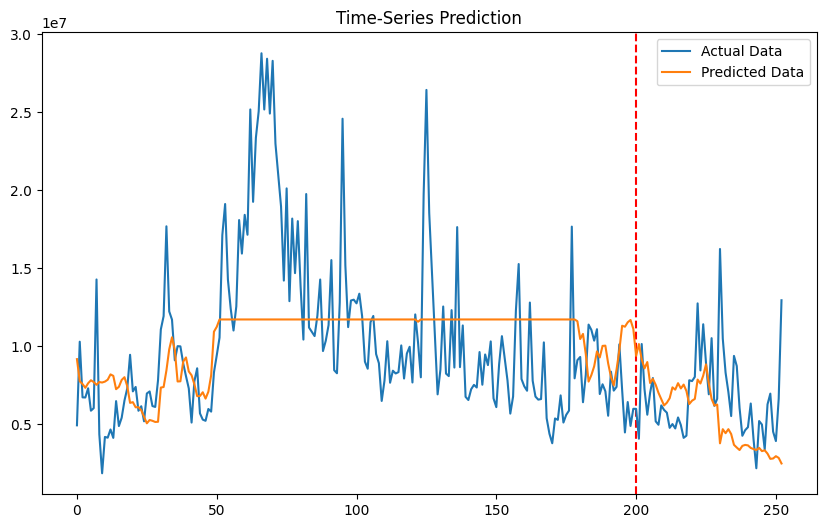

In [ ]:
# 모델 예측 결과 출력

train_predict = model(df_x_ss)
predicted = train_predict.data.numpy()
label_y = df_y_ms.data.numpy()

predicted = ms.inverse_transform(predicted) # 모델 학습을 위해 전처리했던 것을 해제
label_y = ms.inverse_transform(label_y)
plt.figure(figsize=(10, 6))
plt.axvline(x=200, c='r', linestyle='--')

plt.plot(label_y, label='Actual Data')
plt.plot(predicted, label='Predicted Data')
plt.title('Time-Series Prediction')
plt.legend()
plt.show()